# NewsBot 2.0 — Quickstart

NewsBot Intelligence System 2.0 — ITAI 2373. Run from a cloned project root. Model downloads require internet. Results are measured only when cells actually execute.

## 1. Clone, install and fetch BBC data

In [1]:
from pathlib import Path
import os, sys, subprocess

REPO = "https://github.com/iamhuongthn/ITAI2373-NewsBot-Final.git"
PROJECT_DIR = Path("/content/ITAI2373-NewsBot-Final")

if "google.colab" in sys.modules:
    if not (PROJECT_DIR / "requirements.txt").exists():
        subprocess.run(["git", "clone", REPO, str(PROJECT_DIR)], check=True)
    os.chdir(PROJECT_DIR)
else:
    if not Path("requirements.txt").exists():
        raise FileNotFoundError("Run from the NewsBot project root, or open in Google Colab")

print("Project directory:", Path.cwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-U", "pip", "setuptools", "wheel"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-U", "plotly", "kaleido"], check=True)
subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
subprocess.run([sys.executable, "scripts/setup_data.py"], check=True)
print("Setup complete")

Project directory: /content/ITAI2373-NewsBot-Final
Setup complete


## 2. Validate dataset

In [2]:
from config.settings import DATASET, MODEL
from src.data_processing.data_validator import load_bbc
from src.engine import NewsBotEngine
import pandas as pd
news=load_bbc(DATASET)
print('Unique BBC articles:',len(news))
display(news.head(3))

Unique BBC articles: 1440


,article_id,text,category,source,published_at
0,bbc_0,worldcom ex-boss launches defence lawyers defe...,business,BBC Kaggle historical corpus,NaT
1,bbc_1,german business confidence slides german busin...,business,BBC Kaggle historical corpus,NaT
2,bbc_2,bbc poll indicates economic gloom citizens in ...,business,BBC Kaggle historical corpus,NaT


## 3. Train or load classifier

In [3]:
engine=NewsBotEngine(DATASET,MODEL)
print('Model:',engine.classifier.predict('Technology companies release new software and computer systems.'))

Model: {'category': 'tech', 'estimated_probability': 0.9859, 'alternatives': [{'category': 'business', 'estimated_probability': 0.0091}, {'category': 'entertainment', 'estimated_probability': 0.0029}], 'note': 'Probabilities are not calibrated confidence guarantees.'}


## 4. Topic modeling: LDA and NMF

In [4]:
from src.analysis.topic_modeler import TopicModeler

topic_models = {}
for method in ("lda", "nmf"):
    print(f"Training {method.upper()}...")
    tm = TopicModeler(n_topics=7, method=method, random_state=42)
    tm.fit_transform(news.text.tolist())
    topic_models[method] = tm
    for topic_id in range(tm.n_topics):
        print(f"Topic {topic_id}:", ", ".join(tm.get_topic_words(topic_id, 10)))
    display(tm.visualize_topics())

Training LDA...
Topic 0: said, people, mobile, net, use, users, phone, new, software, service
Topic 1: film, best, said, year, new, awards, music, won, award, star
Topic 2: said, mr, government, labour, people, election, blair, party, minister, new
Topic 3: said, mr, court, company, yukos, case, law, trial, fraud, legal
Topic 4: said, game, england, time, year, win, world, team, players, cup
Topic 5: games, music, said, game, technology, video, apple, like, media, players
Topic 6: said, year, market, growth, sales, 2004, economy, new, firm, china


Training NMF...
Topic 0: chelsea, game, win, cup, final, arsenal, season, open, league, club
Topic 1: labour, mr, election, blair, brown, party, tax, howard, prime, minister
Topic 2: growth, economy, sales, economic, dollar, year, 2004, rates, bank, prices
Topic 3: film, best, awards, award, actor, actress, oscar, films, won, director
Topic 4: mobile, people, music, phone, broadband, technology, said, phones, digital, users
Topic 5: said, mr, government, yukos, eu, law, court, company, firm, deal
Topic 6: england, wales, ireland, robinson, france, game, rugby, nations, half, scotland


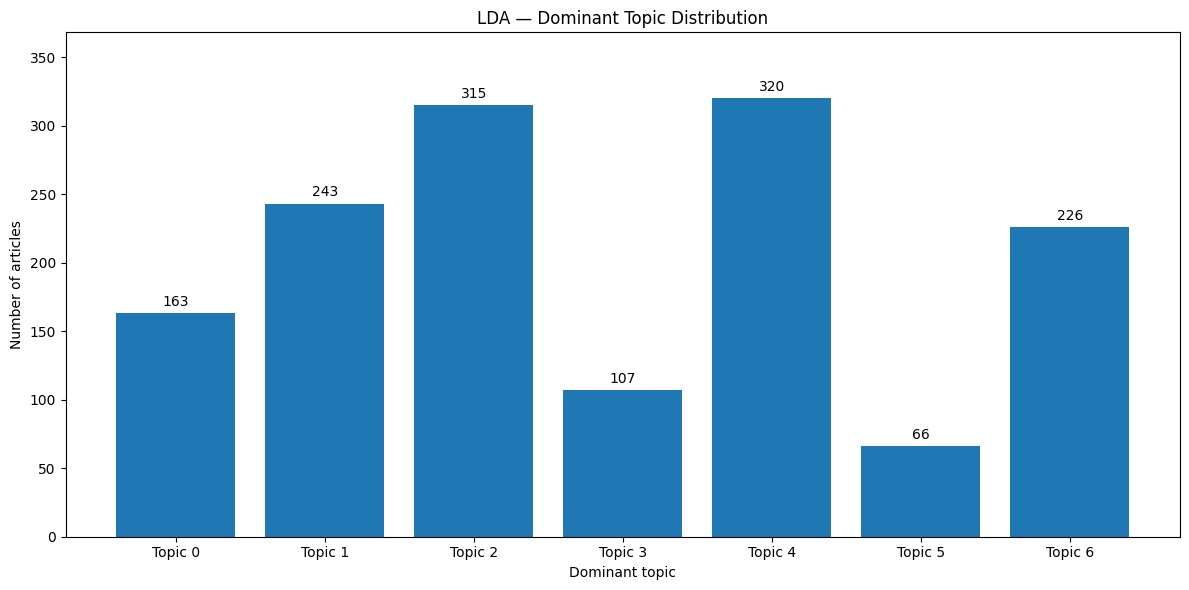

Saved LDA CSV, HTML, and PNG: results/figures/lda_topic_keywords.png


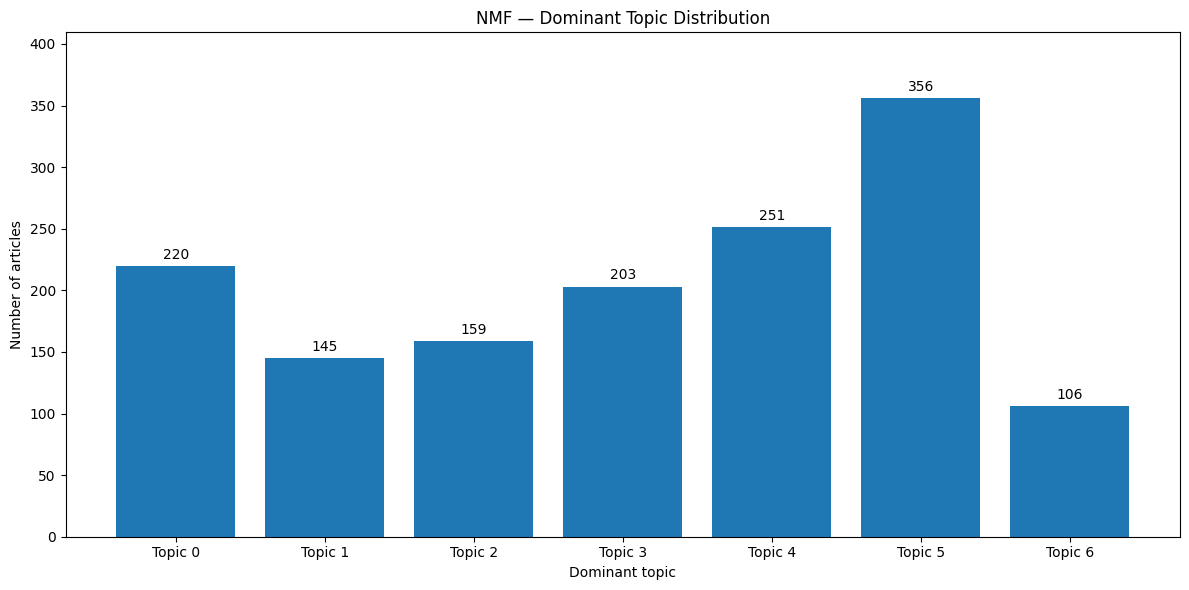

Saved NMF CSV, HTML, and PNG: results/figures/nmf_topic_keywords.png
All seven topic exports saved successfully.


In [5]:
# ============================================================
# NewsBot 2.0 - Export LDA & NMF Topics (NO KALEIDO / CHROME)
# Requires: topic_models from the preceding cell
# Saves: CSV, interactive Plotly HTML, static Matplotlib PNG
# ============================================================
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

fig_dir = Path("results/figures")
eval_dir = Path("evaluation")
fig_dir.mkdir(parents=True, exist_ok=True)
eval_dir.mkdir(parents=True, exist_ok=True)

if not all(m in topic_models for m in ("lda", "nmf")):
    raise RuntimeError("Run the preceding topic-model training cell first.")

topic_tables = []
for method in ("lda", "nmf"):
    tm = topic_models[method]  # reuse the already fitted model
    n_topics = tm.n_topics
    rows = [{
        "model": method.upper(),
        "topic_id": topic_id,
        "top_keywords": ", ".join(tm.get_topic_words(topic_id, 10)),
    } for topic_id in range(n_topics)]
    topic_df = pd.DataFrame(rows)
    topic_df.to_csv(eval_dir / f"{method}_topic_keywords.csv", index=False)
    topic_tables.append(topic_df)

    # Keep original interactive Plotly visualization (no Chrome needed).
    interactive_fig = tm.visualize_topics()
    interactive_fig.write_html(
        str(fig_dir / f"{method}_topic_keywords.html"),
        include_plotlyjs="cdn"
    )
    display(interactive_fig)

    # Static Matplotlib chart of dominant-topic article counts.
    # Uses the same fitted topic weights as the interactive chart.
    dominant_topics = np.argmax(tm.topic_weights, axis=1)
    counts = np.bincount(dominant_topics, minlength=n_topics)
    labels = [f"Topic {i}" for i in range(n_topics)]
    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.bar(labels, counts)
    ax.bar_label(bars, padding=3)
    ax.set_title(f"{method.upper()} — Dominant Topic Distribution")
    ax.set_xlabel("Dominant topic")
    ax.set_ylabel("Number of articles")
    ax.set_ylim(0, max(counts) * 1.15 if max(counts) else 1)
    fig.tight_layout()
    png_path = fig_dir / f"{method}_topic_keywords.png"
    fig.savefig(png_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved {method.upper()} CSV, HTML, and PNG: {png_path}")

combined = pd.concat(topic_tables, ignore_index=True)
combined.to_csv(eval_dir / "topic_keywords_combined.csv", index=False)

required = [
    eval_dir / "lda_topic_keywords.csv",
    eval_dir / "nmf_topic_keywords.csv",
    eval_dir / "topic_keywords_combined.csv",
    fig_dir / "lda_topic_keywords.html",
    fig_dir / "nmf_topic_keywords.html",
    fig_dir / "lda_topic_keywords.png",
    fig_dir / "nmf_topic_keywords.png",
]
missing = [str(p) for p in required if not p.is_file() or p.stat().st_size == 0]
if missing:
    raise RuntimeError(f"Missing or empty topic exports: {missing}")
print("All seven topic exports saved successfully.")


## 5. Article analysis

In [6]:
sample=news.iloc[0]['text']
print('Sentiment:',engine.sentiment(sample))
print('Entities:',engine.entities(sample[:1500])[:8])

Sentiment: {'label': 'negative', 'scores': {'neg': 0.13, 'neu': 0.806, 'pos': 0.064, 'compound': -0.9609}}
Entities: [{'text': 'first', 'label': 'ORDINAL', 'start': 168, 'end': 173}, {'text': 'cynthia cooper', 'label': 'PERSON', 'start': 183, 'end': 197}, {'text': 'us', 'label': 'GPE', 'start': 299, 'end': 301}, {'text': '2002', 'label': 'DATE', 'start': 320, 'end': 324}, {'text': '5.7bn', 'label': 'MONEY', 'start': 409, 'end': 414}, {'text': 'new york', 'label': 'GPE', 'start': 772, 'end': 780}, {'text': 'wednesday', 'label': 'DATE', 'start': 784, 'end': 793}, {'text': 'arthur andersen', 'label': 'PERSON', 'start': 817, 'end': 832}]


## 6. Semantic retrieval (downloads model)

In [7]:
results=engine.search('technology companies internet and software',top_k=3)
for result in results:print(result['index'],round(result['score'],3),result['text'][:120])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/45 [00:00<?, ?it/s]

1377 0.6 uk firms embracing e-commerce uk firms are embracing internet trading opportunities as never before e-commerce minister 
1374 0.482 yahoo moves into desktop search internet giant yahoo has launched software to allow people to search e-mail and other fi
203 0.473 net fingerprints combat attacks eighty large net service firms have switched on software to spot and stop net attacks au


## 7. Summarization (downloads model)

In [8]:
print(engine.summarize(sample[:2200]))

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Device set to use cpu


 whistleblower cynthia cooper alerted directors to irregular accounting practices at the us telecoms giant in 2002 . Her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud . mr ebbers has pleaded not guilty to charges of fraud and conspiracy .


## 8. Multilingual detection and translation (downloads model)


In [9]:
text_vi = "Việt Nam đang phát triển công nghệ trí tuệ nhân tạo."
print("Detected language:", engine.language.detect(text_vi))

# This downloads the Helsinki-NLP vi->en model on first use; internet is required.
# Translation errors are surfaced rather than silently treated as success.
translated = engine.translate(text_vi, source="vi", target="en")
print("Vietnamese to English:", translated)

from pathlib import Path
import json
Path("evaluation").mkdir(exist_ok=True)
Path("evaluation/translation_examples.json").write_text(
    json.dumps({"source_language": "vi", "target_language": "en",
                "source_text": text_vi, "translation": translated},
               ensure_ascii=False, indent=2), encoding="utf-8")

Detected language: vi


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/289M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/289M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

... (2 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

Device set to use cpu


Vietnamese to English: Vietnam is developing artificial intelligence technology.


207

## 9. Conversational search and follow-up

In [10]:
from src.conversation.interface import ConversationalInterface

bot = ConversationalInterface(engine)
queries = [
    "Find technology news about software",
    "What is the sentiment of the first article?",
    "Summarize that article",
    "What organizations are mentioned in it?"
]
conversation_trace = []
for query in queries:
    response = bot.ask(query)
    conversation_trace.append({"query": query, "response": response,
                               "selected_article_id": bot.selected_index})
    print("\nUSER:", query)
    print("NEWSBOT:", str(response)[:1200])

ids = [turn["selected_article_id"] for turn in conversation_trace]
assert ids[0] is not None, "Search did not select an article"
assert len(set(ids)) == 1, "Follow-ups did not preserve the selected article"
assert [x["response"].get("intent") for x in conversation_trace] == ["search", "sentiment", "summarize", "entities"]
print("Conversation state and intent checks passed. Selected article:", ids[0])


USER: Find technology news about software
NEWSBOT: {'intent': 'search', 'results': [{'index': 1347, 'score': 0.47257140278816223, 'text': 'software watching while you work software that can not only monitor every keystroke and action performed at a pc but also be used as legally binding evidence of wrong-doing has been unveiled. worries about cyber-crime and sabotage have prompted many employers to consider monitoring employees. the developers behind the system claim it is a break-through in the way data is monitored and stored. but privacy advocates are concerned by the invasive nature of such software. the system is a joint ventu'}, {'index': 298, 'score': 0.4685581922531128, 'text': 'microsoft takes on desktop search microsoft has entered the desktop search fray releasing a test version of its tool to find documents e-mails and other files on a pc hard drive. the beta program only works on pcs running windows xp or windows 2000. the desktop search market is becoming increasingly cr

## 10. Save evaluation examples and run automated tests

Run the next two code cells **after** classification, topic modeling, semantic search, summarization, translation, and conversation have completed. They save reproducible example outputs under `evaluation/` and execute the project's `pytest` suite. These examples demonstrate functionality; they are **not** formal retrieval, summarization, or translation accuracy metrics.

In [11]:
import json
import pandas as pd
from pathlib import Path

out = Path("evaluation")
out.mkdir(parents=True, exist_ok=True)
query = "technology companies internet and software"
search_results = engine.search(query, top_k=3)
pd.DataFrame([{"query": query, "article_index": r["index"],
               "similarity_score": r["score"], "article_excerpt": r["text"][:300]}
              for r in search_results]).to_csv(out / "semantic_search_examples.csv", index=False)

summary = engine.summarize(sample[:2200])
pd.DataFrame([{"article_excerpt": sample[:2200], "generated_summary": summary}]).to_csv(
    out / "summarization_examples.csv", index=False)

analysis = {"sentiment": engine.sentiment(sample), "entities": engine.entities(sample[:1500])}
(out / "article_analysis_example.json").write_text(
    json.dumps(analysis, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
(out / "conversation_examples.json").write_text(
    json.dumps(conversation_trace, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Saved semantic search, summarization, analysis and contextual conversation evidence")

Saved semantic search, summarization, analysis and contextual conversation evidence


In [12]:
from pathlib import Path
import subprocess, sys

Path("evaluation").mkdir(exist_ok=True)
result = subprocess.run([sys.executable, "-m", "pytest", "-q"], capture_output=True, text=True)
report = result.stdout + "\n" + result.stderr
Path("evaluation/pytest_results.txt").write_text(report, encoding="utf-8")
print(report)
print("Exit code:", result.returncode)
if result.returncode != 0:
    raise RuntimeError("Tests failed; inspect evaluation/pytest_results.txt")

.................                                                        [100%]
17 passed in 2.71s


Exit code: 0


## 11. Export evaluation evidence and download ZIP

Run this **last**. It packages the saved CSV/JSON reports, pytest output, and topic charts into `NewsBot2_Results.zip`. It validates the required files before downloading. PNG exports are optional when Plotly/Kaleido cannot render them; HTML charts are retained.

In [13]:
from pathlib import Path
import zipfile

folders = [Path("evaluation"), Path("results/figures")]
zip_path = Path("/content/NewsBot2_Results.zip") if Path("/content").exists() else Path("NewsBot2_Results.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for folder in folders:
        if folder.exists():
            for path in folder.rglob("*"):
                if path.is_file():
                    archive.write(path, arcname=str(path))

required = [
    "evaluation/lda_topic_keywords.csv", "evaluation/nmf_topic_keywords.csv",
    "evaluation/topic_keywords_combined.csv", "evaluation/semantic_search_examples.csv",
    "evaluation/summarization_examples.csv", "evaluation/article_analysis_example.json",
    "evaluation/conversation_examples.json", "evaluation/translation_examples.json",
    "evaluation/pytest_results.txt", "results/figures/lda_topic_keywords.html",
    "results/figures/nmf_topic_keywords.html"
]
with zipfile.ZipFile(zip_path) as archive:
    included = set(archive.namelist())
    print("Files included in ZIP:")
    for name in sorted(included):
        print(" -", name)
    missing = [name for name in required if name not in included]
    if missing:
        raise RuntimeError(f"ZIP missing expected files: {missing}")
    for method in ("lda", "nmf"):
        png = f"results/figures/{method}_topic_keywords.png"
        if png not in included:
            print("Optional PNG missing:", png, "(HTML chart is included)")

print("Results ZIP ready:", zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Not in Colab; retrieve ZIP from", zip_path)

Files included in ZIP:
 - evaluation/README.md
 - evaluation/article_analysis_example.json
 - evaluation/conversation_examples.json
 - evaluation/lda_topic_keywords.csv
 - evaluation/nmf_topic_keywords.csv
 - evaluation/pytest_results.txt
 - evaluation/semantic_search_examples.csv
 - evaluation/summarization_examples.csv
 - evaluation/topic_keywords_combined.csv
 - evaluation/translation_examples.json
 - results/figures/.gitkeep
 - results/figures/lda_topic_keywords.html
 - results/figures/lda_topic_keywords.png
 - results/figures/nmf_topic_keywords.html
 - results/figures/nmf_topic_keywords.png
Results ZIP ready: /content/NewsBot2_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>